# Requirement 4 — Non-stationary environment: Gaussian constellation check

This notebook is a **focused test of the slightly non-stationary environment**
(`ola/environments/non_stationary.py`), and in particular of whether the
**Gaussian constellation** — one Gaussian distribution per interval, used to
sample the highest competing bids — is generated correctly.

We proceed in steps:

1. Build a **simple base example** of the environment.
2. Check the **structure** of the constellation (one Gaussian per interval, valid
   shapes, means inside the admissible box `[0.1, 0.9]`, covariances symmetric /
   positive-definite / spectrally bounded by `max_std`).
3. Check the **pairwise symmetric-KL divergence** between intervals against the
   requested `target_skl` (this is what makes the regimes "controllably different").
4. Check that the **sampled competing bids actually follow** the per-interval
   Gaussian (empirical mean / covariance vs. theoretical), with a 2-D visual.
5. Visualise the **competing-bid sequence** over time with the interval boundaries.

In [54]:
# Setup: make the repo importable and load dependencies
import os
import sys

# The notebook lives in notebooks/; the repo root is its parent.
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

import numpy as np
import matplotlib.pyplot as plt

from ola.environments.non_stationary import NonStationaryMultiCampaignEnvironment
from ola.utils.constellation.utils import symmetric_kullback_leibler
from ola.utils.constellation.constellation import MU_LO, MU_HI

# print("repo_root:", repo_root)
print("MU_LO, MU_HI (admissible mean box):", MU_LO, MU_HI)

MU_LO, MU_HI (admissible mean box): 0.1 0.9


## 1. A simple base example

We deliberately keep it small and 2-dimensional (`N = 2` campaigns) so that the
per-interval Gaussians can be drawn on a plane. We use:

- `number_of_intervals = 3` -> three regimes, three Gaussians;
- `target_skl = 2.0` -> the requested pairwise symmetric-KL divergence;
- a moderately long `horizon` so each interval has enough samples for the
  empirical mean/covariance check to be meaningful;
- both seeds fixed (`constellation_seed`, `random_seed`) for reproducibility.

In [55]:
N = 2
NUM_INTERVALS = 3
TARGET_SKL = 2.0
HORIZON = 3000

env = NonStationaryMultiCampaignEnvironment(
    number_of_campaigns=N,
    horizon=HORIZON,
    number_of_intervals=NUM_INTERVALS,
    budget=10000,                               # irrelevant to sequence generation
    target_skl=TARGET_SKL,
    max_std=0.1,
    constellation_seed=0,
    random_seed=0,
)

info = env.reset()["info"]
print("number_of_campaigns :", info["number_of_campaigns"])
print("number_of_intervals :", info["number_of_intervals"])
print("interval_lengths    :", info["interval_lengths"])
print("interval_boundaries :", info["interval_boundaries"])
print("horizon             :", info["horizon"])
print("competing-bid matrix shape:", env.highest_competing_bids.shape)

number_of_campaigns : 2
number_of_intervals : 3
interval_lengths    : [1000, 1000, 1000]
interval_boundaries : [0, 1000, 2000, 3000]
horizon             : 3000
competing-bid matrix shape: (3000, 2)


## 2. Structural checks on the constellation

`env.constellation` is a list of `(mu, sigma)` pairs — **one Gaussian per
interval**. We verify:

- exactly `number_of_intervals` Gaussians;
- `mu` has shape `(N,)`, `sigma` has shape `(N, N)`;
- every mean lies inside the admissible box `[MU_LO, MU_HI] = [0.1, 0.9]`
  (enforced by the constellation builder, keeps samples away from the `[0, 1]`
  clipping walls);
- every covariance is **symmetric** and **positive-definite**;
- the covariance spectrum is bounded by `max_std**2` (the spectral bound the
  builder promises).

In [56]:
modes = env.constellation
max_std = env.max_std
tol = 1e-9

print(f"number of Gaussians in constellation : {len(modes)} "
      f"(expected {env.number_of_intervals})")
assert len(modes) == env.number_of_intervals, "wrong number of modes!"

all_ok = True
for k, (mu, sigma) in enumerate(modes):
    mu = np.asarray(mu); sigma = np.asarray(sigma)
    shape_ok = mu.shape == (N,) and sigma.shape == (N, N)
    sym_ok = np.allclose(sigma, sigma.T, atol=tol)
    eig = np.linalg.eigvalsh(sigma)
    pd_ok = np.all(eig > 0)
    spec_ok = eig.max() <= max_std**2 + 1e-9
    mean_ok = np.all((mu >= MU_LO - tol) & (mu <= MU_HI + tol))
    ok = shape_ok and sym_ok and pd_ok and spec_ok and mean_ok
    all_ok = all_ok and ok
    print(f"\n--- interval / mode {k} ---")
    print("  mu               :", np.round(mu, 4),
          "| in [0.1, 0.9]?", mean_ok)
    print("  sigma diag (var) :", np.round(np.diag(sigma), 5))
    print("  sigma eigenvalues:", np.round(eig, 5),
          "| max <= max_std^2 =", round(max_std**2, 5), "?", spec_ok)
    print("  shapes ok:", shape_ok, "| symmetric:", sym_ok, "| pos-def:", pd_ok)

print("\nALL STRUCTURAL CHECKS PASSED:", all_ok)

number of Gaussians in constellation : 3 (expected 3)

--- interval / mode 0 ---
  mu               : [0.4501 0.8134] | in [0.1, 0.9]? True
  sigma diag (var) : [0.00888 0.00636]
  sigma eigenvalues: [0.00525 0.01   ] | max <= max_std^2 = 0.01 ? True
  shapes ok: True | symmetric: True | pos-def: True

--- interval / mode 1 ---
  mu               : [0.5325 0.7438] | in [0.1, 0.9]? True
  sigma diag (var) : [0.00973 0.00551]
  sigma eigenvalues: [0.00525 0.01   ] | max <= max_std^2 = 0.01 ? True
  shapes ok: True | symmetric: True | pos-def: True

--- interval / mode 2 ---
  mu               : [0.5838 0.8451] | in [0.1, 0.9]? True
  sigma diag (var) : [0.00985 0.00539]
  sigma eigenvalues: [0.00525 0.01   ] | max <= max_std^2 = 0.01 ? True
  shapes ok: True | symmetric: True | pos-def: True

ALL STRUCTURAL CHECKS PASSED: True


## 3. Pairwise symmetric-KL divergence vs. `target_skl`

The whole point of the constellation is that consecutive regimes differ by a
*controlled* amount. We recompute the full pairwise symmetric-KL (sKL) matrix
from the stored Gaussians and compare the off-diagonal entries to the requested
`target_skl`.

The default builder (`generate_constellation_gd_rotation`) optimises every pair
towards a single scalar target, so we expect every off-diagonal entry to sit
**close to** `target_skl` (a few outliers slightly off are acceptable on hard
instances, as documented in the constellation module).

In [57]:
M = env.number_of_intervals
skl = np.zeros((M, M))
for i in range(M):
    for j in range(i + 1, M):
        s = symmetric_kullback_leibler(modes[i], modes[j])
        skl[i, j] = s
        skl[j, i] = s

off_diag = skl[~np.eye(M, dtype=bool)]
print("target_skl           :", TARGET_SKL)
print("pairwise sKL matrix  :\n", np.round(skl, 4))
print("\noff-diagonal min/mean/max:",
      round(off_diag.min(), 4), round(off_diag.mean(), 4), round(off_diag.max(), 4))
print("max |sKL - target|   :", round(np.abs(off_diag - TARGET_SKL).max(), 4))

target_skl           : 2.0
pairwise sKL matrix  :
 [[0. 2. 2.]
 [2. 0. 2.]
 [2. 2. 0.]]

off-diagonal min/mean/max: 2.0 2.0 2.0
max |sKL - target|   : 0.0


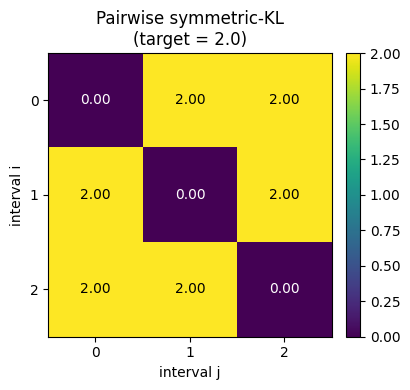

In [58]:
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(skl, cmap="viridis")
ax.set_title(f"Pairwise symmetric-KL\n(target = {TARGET_SKL})")
ax.set_xlabel("interval j"); ax.set_ylabel("interval i")
ax.set_xticks(range(M)); ax.set_yticks(range(M))
for i in range(M):
    for j in range(M):
        ax.text(j, i, f"{skl[i, j]:.2f}", ha="center", va="center",
                color="w" if skl[i, j] < skl.max() * 0.6 else "k")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

## 4. Do the sampled competing bids follow the per-interval Gaussians?

For each interval we collect the rounds assigned to it (via `phase_ids`), and
compare the **empirical** mean / covariance of the sampled highest competing bids
to the **theoretical** `(mu, sigma)` of that interval's Gaussian.

Because samples are clipped to `[0, 1]`, a tiny bias is expected; with means in
`[0.1, 0.9]` and `max_std = 0.1` clipping is rare, so empirical and theoretical
should match closely.

In [59]:
hcb = env.highest_competing_bids
phase_ids = env.phase_ids

for k in range(M):
    mask = phase_ids == k
    samples = hcb[mask]
    emp_mean = samples.mean(axis=0)
    emp_cov = np.cov(samples, rowvar=False)
    th_mean, th_cov = modes[k]
    print(f"--- interval {k}: {mask.sum()} samples ---")
    print("  empirical mean :", np.round(emp_mean, 4),
          "| theoretical mean:", np.round(th_mean, 4),
          "| max|diff| =", round(np.abs(emp_mean - th_mean).max(), 4))
    print("  empirical cov  :\n", np.round(emp_cov, 5))
    print("  theoretical cov:\n", np.round(np.asarray(th_cov), 5))
    print("  max|cov diff|  :", round(np.abs(emp_cov - np.asarray(th_cov)).max(), 5), "\n")

--- interval 0: 1000 samples ---
  empirical mean : [0.4536 0.813 ] | theoretical mean: [0.4501 0.8134] | max|diff| = 0.0035
  empirical cov  :
 [[0.00902 0.00232]
 [0.00232 0.00633]]
  theoretical cov:
 [[0.00888 0.00202]
 [0.00202 0.00636]]
  max|cov diff|  : 0.00031 

--- interval 1: 1000 samples ---
  empirical mean : [0.534  0.7452] | theoretical mean: [0.5325 0.7438] | max|diff| = 0.0015
  empirical cov  :
 [[0.00929 0.00133]
 [0.00133 0.00574]]
  theoretical cov:
 [[0.00973 0.0011 ]
 [0.0011  0.00551]]
  max|cov diff|  : 0.00044 

--- interval 2: 1000 samples ---
  empirical mean : [0.5809 0.846 ] | theoretical mean: [0.5838 0.8451] | max|diff| = 0.0029
  empirical cov  :
 [[0.00967 0.00138]
 [0.00138 0.00522]]
  theoretical cov:
 [[0.00985 0.00082]
 [0.00082 0.00539]]
  max|cov diff|  : 0.00055 



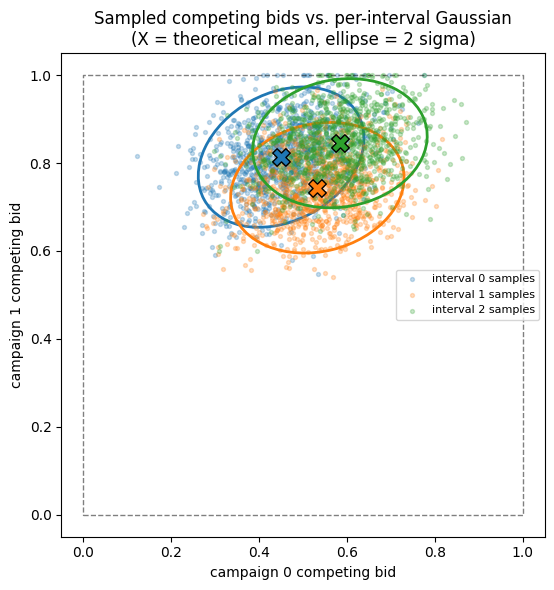

In [60]:
# 2-D scatter of the sampled competing bids per interval, with the
# theoretical mean and a 2-sigma covariance ellipse overlaid.
from matplotlib.patches import Ellipse

def cov_ellipse(ax, mean, cov, n_std=2.0, **kw):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    width, height = 2 * n_std * np.sqrt(vals)
    ax.add_patch(Ellipse(mean, width, height, angle=angle, fill=False, **kw))

colors = plt.cm.tab10(np.arange(M))
fig, ax = plt.subplots(figsize=(6, 6))
for k in range(M):
    mask = phase_ids == k
    s = hcb[mask]
    ax.scatter(s[:, 0], s[:, 1], s=8, alpha=0.25, color=colors[k],
               label=f"interval {k} samples")
    mu, cov = modes[k]
    mu = np.asarray(mu); cov = np.asarray(cov)
    ax.scatter(*mu, color=colors[k], edgecolor="k", s=160, marker="X", zorder=5)
    cov_ellipse(ax, mu, cov, n_std=2.0, edgecolor=colors[k], lw=2)

# draw the [0,1] auction / clipping box
ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], "k--", lw=1, alpha=0.5)
ax.set_title("Sampled competing bids vs. per-interval Gaussian\n"
             "(X = theoretical mean, ellipse = 2 sigma)")
ax.set_xlabel("campaign 0 competing bid"); ax.set_ylabel("campaign 1 competing bid")
ax.set_aspect("equal"); ax.legend(loc="best", fontsize=8)
plt.tight_layout(); plt.show()

## 5. Competing-bid sequence over time

Finally we plot the realised highest competing bid of each campaign over the
horizon, with vertical lines at the interval boundaries. The per-interval mean
level should visibly shift at each boundary, confirming the non-stationary
structure is wired correctly.

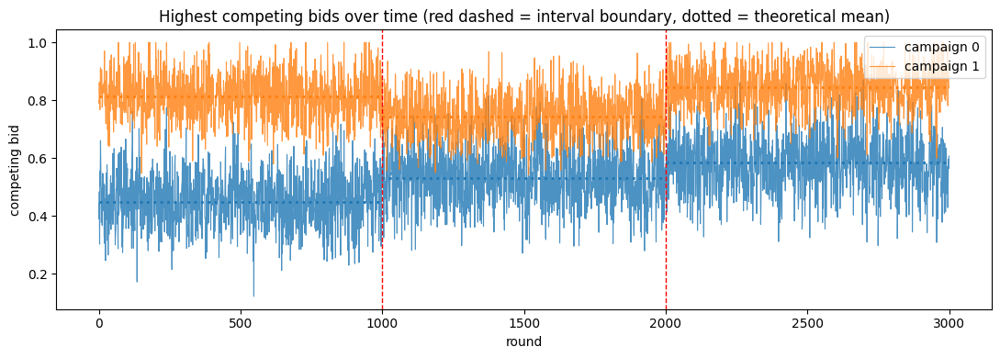

In [61]:
fig, ax = plt.subplots(figsize=(11, 4))
for c in range(N):
    ax.plot(hcb[:, c], lw=0.8, alpha=0.8, label=f"campaign {c}")
for b in env.interval_boundaries[1:-1]:
    ax.axvline(b, color="r", ls="--", lw=1)
# overlay the theoretical per-interval mean for each campaign as a step reference
bounds = env.interval_boundaries
for k in range(M):
    lo, hi = bounds[k], bounds[k + 1]
    for c in range(N):
        ax.hlines(modes[k][0][c], lo, hi, color=colors[c % len(colors)],
                  ls=":", lw=2)
ax.set_title("Highest competing bids over time (red dashed = interval boundary, "
             "dotted = theoretical mean)")
ax.set_xlabel("round"); ax.set_ylabel("competing bid"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## Summary

If the cells above run cleanly:

- **Structure** — there is exactly one Gaussian per interval, with correct
  shapes, means inside `[0.1, 0.9]`, and symmetric / positive-definite /
  spectrally-bounded covariances.
- **Separation** — the pairwise symmetric-KL divergences cluster around the
  requested `target_skl`, so consecutive regimes are "controllably different".
- **Sampling** — the realised competing bids match their interval's Gaussian
  (empirical mean/covariance ~ theoretical), and the time series clearly shifts
  level at each interval boundary.

Together these confirm the Gaussian constellation is generated and used
correctly by the non-stationary environment.

## Generate easy examples

The following examples are Gaussians constellations generated with different characteristic in order to simply visually inspect the behaviour of the distributions.  

First generated environment is about a 2 campaigns scenario with a small skl divergence (2 as before) and still 3000 as horizon with 3 intervals.

In [62]:
env_2G = NonStationaryMultiCampaignEnvironment(
    number_of_campaigns=2,
    horizon=HORIZON,
    number_of_intervals=NUM_INTERVALS,
    budget=10000,                               # irrelevant to sequence generation
    target_skl=TARGET_SKL,
    max_std=0.1,
    constellation_seed=42,
    random_seed=42,
)

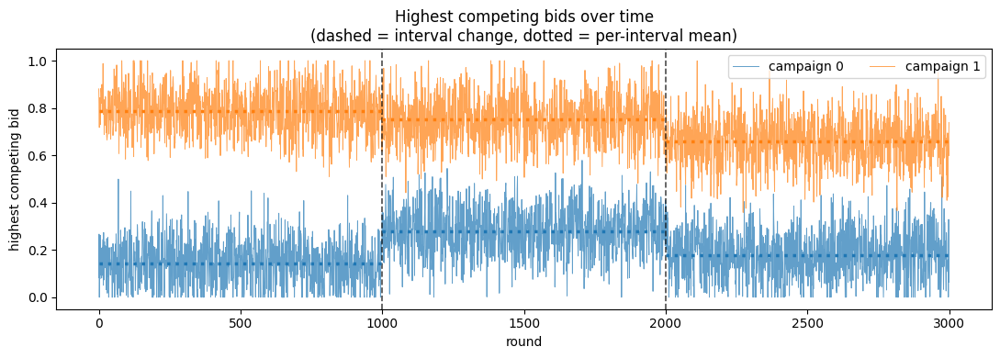

In [63]:
# Get the characteristic from the environment
hcb = env_2G.highest_competing_bids          
boundaries = env_2G.interval_boundaries       
n_campaigns = env_2G.number_of_campaigns
n_intervals = env_2G.number_of_intervals

# Set colors for the plot
colors = plt.cm.tab10(np.arange(n_campaigns))

# Create the figure
fig, ax = plt.subplots(figsize=(11, 4))

# Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
for c in range(n_campaigns):
    ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

# Add a vertical line for each interval change.
for b in boundaries[1:-1]:
    ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

# For every interval add a line for the mean value of the highest competing bids across the interval.
for k in range(n_intervals):
    lo, hi = boundaries[k], boundaries[k + 1]
    seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
    for c in range(n_campaigns):
        ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

# Set title, labels, legend and show the plot.
ax.set_title("Highest competing bids over time" + "\n(dashed = interval change, dotted = per-interval mean)")
ax.set_xlabel("round")
ax.set_ylabel("highest competing bid")
ax.legend(loc="upper right", ncol=n_campaigns)

plt.tight_layout()
plt.show()

In [64]:
modes = env_2G.constellation
max_std = env_2G.max_std

for k, (mu, sigma) in enumerate(modes):
    mu = np.asarray(mu); sigma = np.asarray(sigma)
    eig = np.linalg.eigvalsh(sigma)
    print(f"\n--- interval / mode {k} ---")
    print("  mu               :", np.round(mu, 4))
    print("  sigma diag (var) :", np.round(np.diag(sigma), 5))
    print("  sigma eigenvalues:", np.round(eig, 5))


--- interval / mode 0 ---
  mu               : [0.1465 0.7929]
  sigma diag (var) : [0.01 0.01]
  sigma eigenvalues: [0.01 0.01]

--- interval / mode 1 ---
  mu               : [0.2811 0.7497]
  sigma diag (var) : [0.01 0.01]
  sigma eigenvalues: [0.01 0.01]

--- interval / mode 2 ---
  mu               : [0.1763 0.6547]
  sigma diag (var) : [0.01 0.01]
  sigma eigenvalues: [0.01 0.01]


Case with 2 campaigns, 3 intervals but a high skl.

In [65]:
env_highSKL = NonStationaryMultiCampaignEnvironment(
    number_of_campaigns=2,
    horizon=HORIZON,
    number_of_intervals=NUM_INTERVALS,
    budget=10000,                               # irrelevant to sequence generation
    target_skl=20,
    max_std=0.1,
    constellation_seed=42,
    random_seed=42,
)

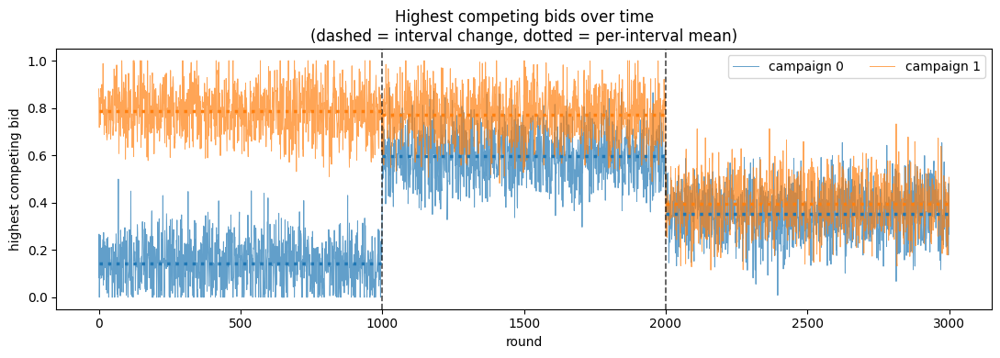

In [66]:
# Get the characteristic from the environment
hcb = env_highSKL.highest_competing_bids          
boundaries = env_highSKL.interval_boundaries       
n_campaigns = env_highSKL.number_of_campaigns
n_intervals = env_highSKL.number_of_intervals

# Set colors for the plot
colors = plt.cm.tab10(np.arange(n_campaigns))

# Create the figure
fig, ax = plt.subplots(figsize=(11, 4))

# Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
for c in range(n_campaigns):
    ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

# Add a vertical line for each interval change.
for b in boundaries[1:-1]:
    ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

# For every interval add a line for the mean value of the highest competing bids across the interval.
for k in range(n_intervals):
    lo, hi = boundaries[k], boundaries[k + 1]
    seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
    for c in range(n_campaigns):
        ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

# Set title, labels, legend and show the plot.
ax.set_title("Highest competing bids over time" + "\n(dashed = interval change, dotted = per-interval mean)")
ax.set_xlabel("round")
ax.set_ylabel("highest competing bid")
ax.legend(loc="upper right", ncol=n_campaigns)

plt.tight_layout()
plt.show()

In [67]:
modes = env_highSKL.constellation
max_std = env_highSKL.max_std

for k, (mu, sigma) in enumerate(modes):
    mu = np.asarray(mu); sigma = np.asarray(sigma)
    eig = np.linalg.eigvalsh(sigma)
    print(f"\n--- interval / mode {k} ---")
    print("  mu               :", np.round(mu, 4))
    print("  sigma diag (var) :", np.round(np.diag(sigma), 5))
    print("  sigma eigenvalues:", np.round(eig, 5))


--- interval / mode 0 ---
  mu               : [0.1465 0.7929]
  sigma diag (var) : [0.01 0.01]
  sigma eigenvalues: [0.01 0.01]

--- interval / mode 1 ---
  mu               : [0.5931 0.7711]
  sigma diag (var) : [0.01 0.01]
  sigma eigenvalues: [0.01 0.01]

--- interval / mode 2 ---
  mu               : [0.3509 0.3952]
  sigma diag (var) : [0.01 0.01]
  sigma eigenvalues: [0.01 0.01]


Case with 2 campaigns, 4 intervals, TARGET_SKL but high max_std.

In [68]:
env_highSTD = NonStationaryMultiCampaignEnvironment(
    number_of_campaigns=2,
    horizon=HORIZON,
    number_of_intervals=4,
    budget=10000,                               # irrelevant to sequence generation
    target_skl=TARGET_SKL,
    max_std=0.2,
    constellation_seed=42,
    random_seed=42,
)

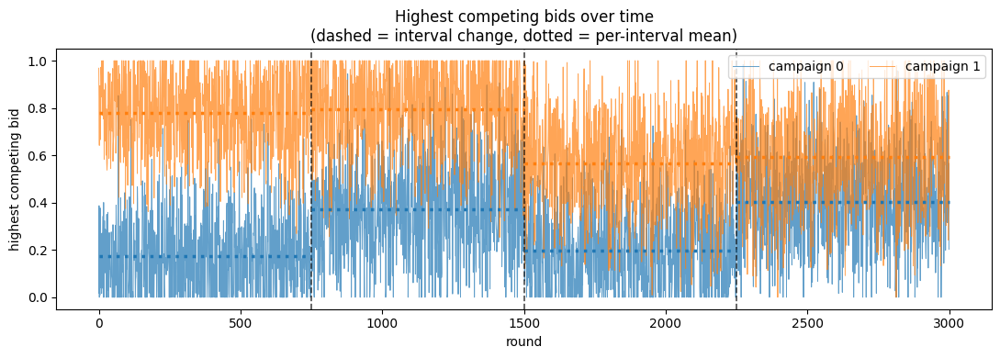

In [69]:
# Get the characteristic from the environment
hcb = env_highSTD.highest_competing_bids          
boundaries = env_highSTD.interval_boundaries       
n_campaigns = env_highSTD.number_of_campaigns
n_intervals = env_highSTD.number_of_intervals

# Set colors for the plot
colors = plt.cm.tab10(np.arange(n_campaigns))

# Create the figure
fig, ax = plt.subplots(figsize=(11, 4))

# Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
for c in range(n_campaigns):
    ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

# Add a vertical line for each interval change.
for b in boundaries[1:-1]:
    ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

# For every interval add a line for the mean value of the highest competing bids across the interval.
for k in range(n_intervals):
    lo, hi = boundaries[k], boundaries[k + 1]
    seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
    for c in range(n_campaigns):
        ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

# Set title, labels, legend and show the plot.
ax.set_title("Highest competing bids over time" + "\n(dashed = interval change, dotted = per-interval mean)")
ax.set_xlabel("round")
ax.set_ylabel("highest competing bid")
ax.legend(loc="upper right", ncol=n_campaigns)

plt.tight_layout()
plt.show()

In [70]:
modes = env_highSTD.constellation
max_std = env_highSTD.max_std

for k, (mu, sigma) in enumerate(modes):
    mu = np.asarray(mu); sigma = np.asarray(sigma)
    eig = np.linalg.eigvalsh(sigma)
    print(f"\n--- interval / mode {k} ---")
    print("  mu               :", np.round(mu, 4))
    print("  sigma diag (var) :", np.round(np.diag(sigma), 5))
    print("  sigma eigenvalues:", np.round(eig, 5))


--- interval / mode 0 ---
  mu               : [0.1465 0.7929]
  sigma diag (var) : [0.04 0.04]
  sigma eigenvalues: [0.04 0.04]

--- interval / mode 1 ---
  mu               : [0.3756 0.8218]
  sigma diag (var) : [0.04 0.04]
  sigma eigenvalues: [0.04 0.04]

--- interval / mode 2 ---
  mu               : [0.1753 0.5638]
  sigma diag (var) : [0.04 0.04]
  sigma eigenvalues: [0.04 0.04]

--- interval / mode 3 ---
  mu               : [0.4044 0.5927]
  sigma diag (var) : [0.04 0.04]
  sigma eigenvalues: [0.04 0.04]


In [71]:
env_base = NonStationaryMultiCampaignEnvironment()

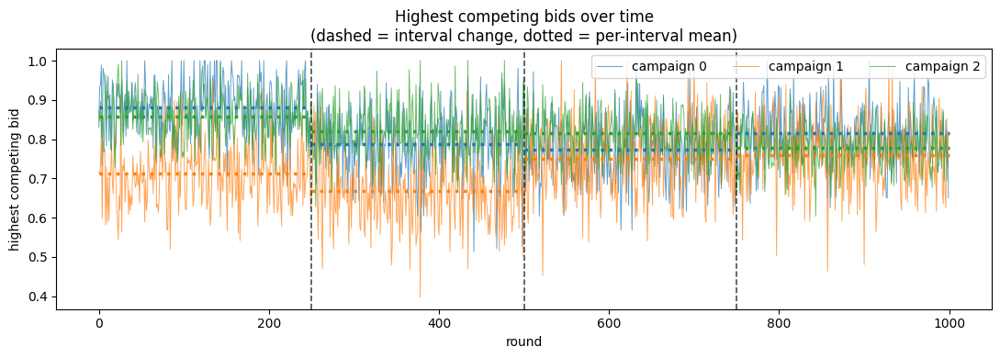

In [72]:
# Get the characteristic from the environment
hcb = env_base.highest_competing_bids          
boundaries = env_base.interval_boundaries       
n_campaigns = env_base.number_of_campaigns
n_intervals = env_base.number_of_intervals

# Set colors for the plot
colors = plt.cm.tab10(np.arange(n_campaigns))

# Create the figure
fig, ax = plt.subplots(figsize=(11, 4))

# Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
for c in range(n_campaigns):
    ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

# Add a vertical line for each interval change.
for b in boundaries[1:-1]:
    ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

# For every interval add a line for the mean value of the highest competing bids across the interval.
for k in range(n_intervals):
    lo, hi = boundaries[k], boundaries[k + 1]
    seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
    for c in range(n_campaigns):
        ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

# Set title, labels, legend and show the plot.
ax.set_title("Highest competing bids over time" + "\n(dashed = interval change, dotted = per-interval mean)")
ax.set_xlabel("round")
ax.set_ylabel("highest competing bid")
ax.legend(loc="upper right", ncol=n_campaigns)

plt.tight_layout()
plt.show()

In [73]:
modes = env_base.constellation
max_std = env_base.max_std

for k, (mu, sigma) in enumerate(modes):
    mu = np.asarray(mu); sigma = np.asarray(sigma)
    eig = np.linalg.eigvalsh(sigma)
    print(f"\n--- interval / mode {k} ---")
    print("  mu               :", np.round(mu, 4))
    print("  sigma diag (var) :", np.round(np.diag(sigma), 5))
    print("  sigma eigenvalues:", np.round(eig, 5))


--- interval / mode 0 ---
  mu               : [0.8757 0.7201 0.8516]
  sigma diag (var) : [0.00631 0.00787 0.0037 ]
  sigma eigenvalues: [0.00109 0.00679 0.01   ]

--- interval / mode 1 ---
  mu               : [0.7901 0.6708 0.8233]
  sigma diag (var) : [0.00658 0.00676 0.00453]
  sigma eigenvalues: [0.00109 0.00679 0.01   ]

--- interval / mode 2 ---
  mu               : [0.7704 0.7534 0.8114]
  sigma diag (var) : [0.00647 0.00833 0.00308]
  sigma eigenvalues: [0.00109 0.00679 0.01   ]

--- interval / mode 3 ---
  mu               : [0.8265 0.7701 0.7763]
  sigma diag (var) : [0.00622 0.00874 0.00291]
  sigma eigenvalues: [0.00109 0.00679 0.01   ]


### Check whether invoking different times the environment with the same characteritstics and the same random seed, the outcome is exactly the same as before. The test has been made on the second shown environment, env_highSKL.

In [74]:
env_highSKL_second = NonStationaryMultiCampaignEnvironment(
    number_of_campaigns=2,
    horizon=HORIZON,
    number_of_intervals=NUM_INTERVALS,
    budget=10000,                               # irrelevant to sequence generation
    target_skl=20,
    max_std=0.1,
    constellation_seed=42,
    random_seed=42,
)

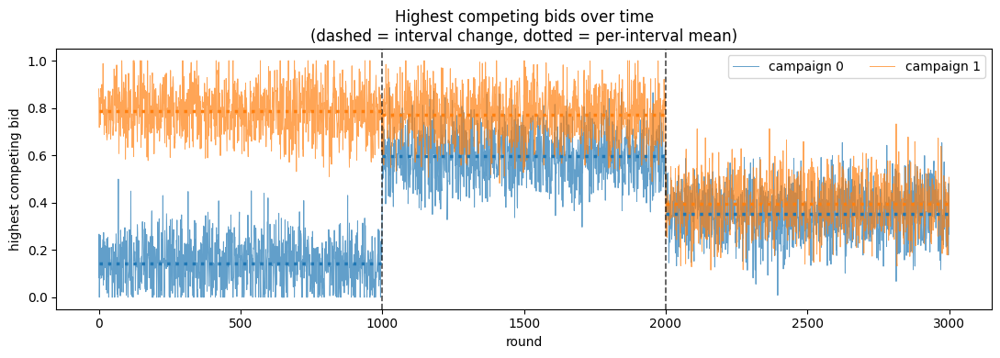

In [75]:
# Get the characteristic from the environment
hcb = env_highSKL_second.highest_competing_bids          
boundaries = env_highSKL_second.interval_boundaries       
n_campaigns = env_highSKL_second.number_of_campaigns
n_intervals = env_highSKL_second.number_of_intervals

# Set colors for the plot
colors = plt.cm.tab10(np.arange(n_campaigns))

# Create the figure
fig, ax = plt.subplots(figsize=(11, 4))

# Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
for c in range(n_campaigns):
    ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

# Add a vertical line for each interval change.
for b in boundaries[1:-1]:
    ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

# For every interval add a line for the mean value of the highest competing bids across the interval.
for k in range(n_intervals):
    lo, hi = boundaries[k], boundaries[k + 1]
    seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
    for c in range(n_campaigns):
        ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

# Set title, labels, legend and show the plot.
ax.set_title("Highest competing bids over time" + "\n(dashed = interval change, dotted = per-interval mean)")
ax.set_xlabel("round")
ax.set_ylabel("highest competing bid")
ax.legend(loc="upper right", ncol=n_campaigns)

plt.tight_layout()
plt.show()

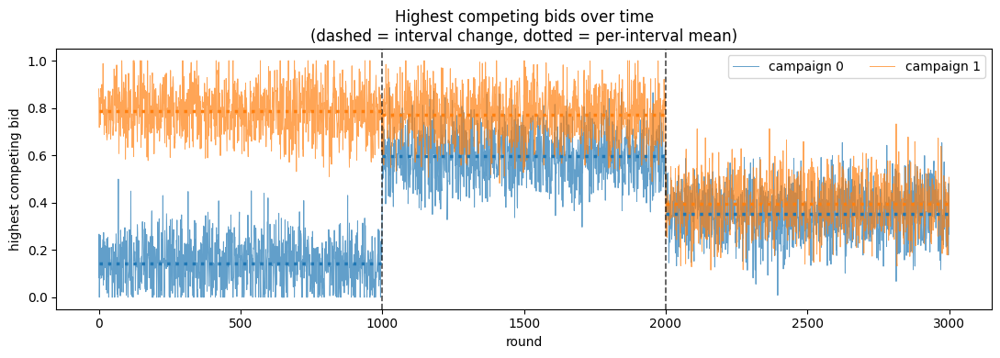

In [76]:
# Get the characteristic from the environment
hcb = env_highSKL.highest_competing_bids          
boundaries = env_highSKL.interval_boundaries       
n_campaigns = env_highSKL.number_of_campaigns
n_intervals = env_highSKL.number_of_intervals

# Set colors for the plot
colors = plt.cm.tab10(np.arange(n_campaigns))

# Create the figure
fig, ax = plt.subplots(figsize=(11, 4))

# Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
for c in range(n_campaigns):
    ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

# Add a vertical line for each interval change.
for b in boundaries[1:-1]:
    ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

# For every interval add a line for the mean value of the highest competing bids across the interval.
for k in range(n_intervals):
    lo, hi = boundaries[k], boundaries[k + 1]
    seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
    for c in range(n_campaigns):
        ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

# Set title, labels, legend and show the plot.
ax.set_title("Highest competing bids over time" + "\n(dashed = interval change, dotted = per-interval mean)")
ax.set_xlabel("round")
ax.set_ylabel("highest competing bid")
ax.legend(loc="upper right", ncol=n_campaigns)

plt.tight_layout()
plt.show()

### Check that by keeping the same seed for the constellation but having a different seed for the sampling, the empirical observations change. Confront the below image with the above one, same charactertistics but different sampling random seed.

In [77]:
env_highSKL_diffSeed = NonStationaryMultiCampaignEnvironment(
    number_of_campaigns=2,
    horizon=HORIZON,
    number_of_intervals=NUM_INTERVALS,
    budget=10000,                               # irrelevant to sequence generation
    target_skl=20,
    max_std=0.1,
    constellation_seed=42,
    random_seed=0,
)

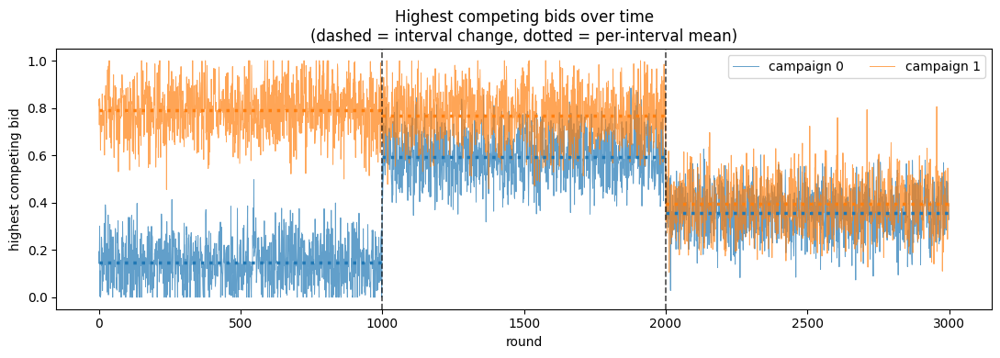

In [78]:
# Get the characteristic from the environment
hcb = env_highSKL_diffSeed.highest_competing_bids          
boundaries = env_highSKL_diffSeed.interval_boundaries       
n_campaigns = env_highSKL_diffSeed.number_of_campaigns
n_intervals = env_highSKL_diffSeed.number_of_intervals

# Set colors for the plot
colors = plt.cm.tab10(np.arange(n_campaigns))

# Create the figure
fig, ax = plt.subplots(figsize=(11, 4))

# Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
for c in range(n_campaigns):
    ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

# Add a vertical line for each interval change.
for b in boundaries[1:-1]:
    ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

# For every interval add a line for the mean value of the highest competing bids across the interval.
for k in range(n_intervals):
    lo, hi = boundaries[k], boundaries[k + 1]
    seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
    for c in range(n_campaigns):
        ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

# Set title, labels, legend and show the plot.
ax.set_title("Highest competing bids over time" + "\n(dashed = interval change, dotted = per-interval mean)")
ax.set_xlabel("round")
ax.set_ylabel("highest competing bid")
ax.legend(loc="upper right", ncol=n_campaigns)

plt.tight_layout()
plt.show()

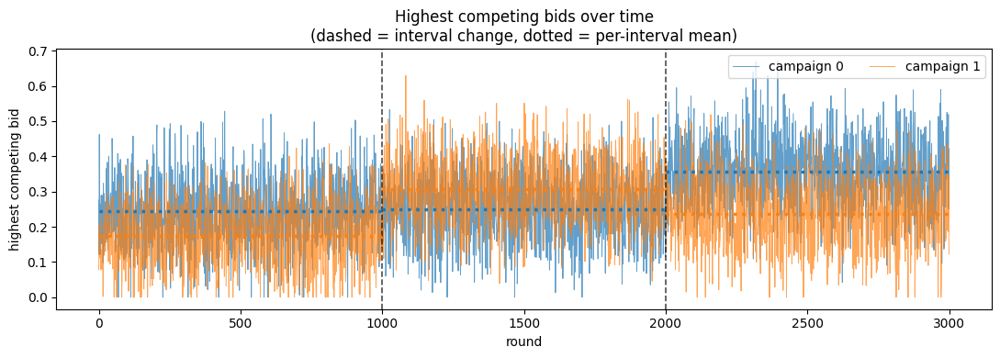


--- interval / mode 0 ---
  mu               : [0.2353 0.1707]

--- interval / mode 1 ---
  mu               : [0.2482 0.3076]

--- interval / mode 2 ---
  mu               : [0.3597 0.2371]


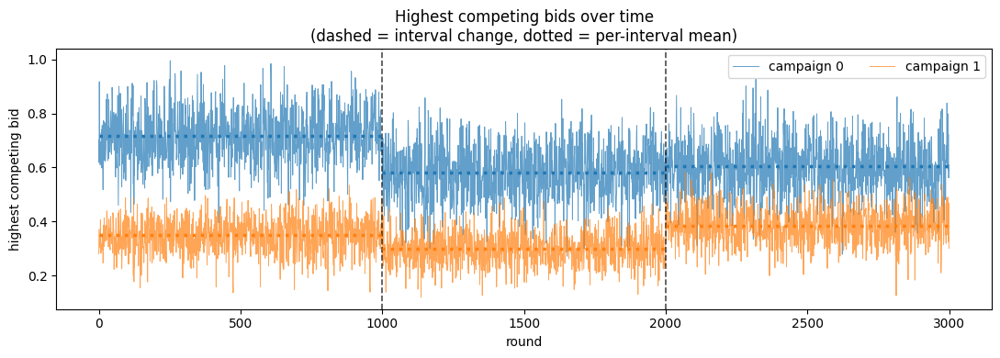


--- interval / mode 0 ---
  mu               : [0.7084 0.348 ]

--- interval / mode 1 ---
  mu               : [0.5812 0.2979]

--- interval / mode 2 ---
  mu               : [0.6075 0.3836]


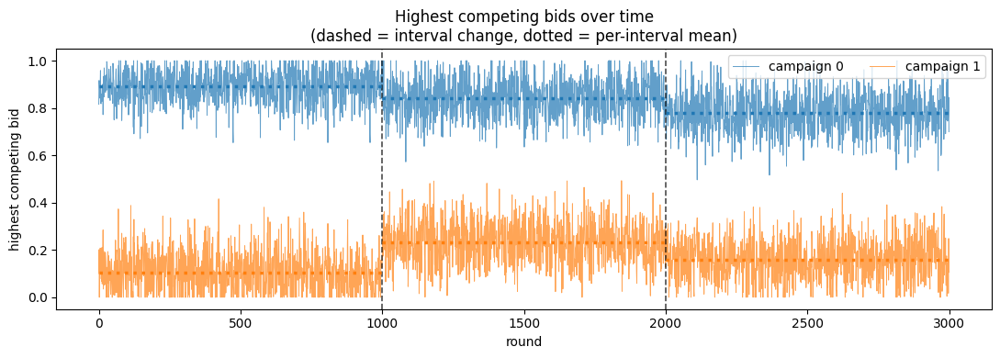


--- interval / mode 0 ---
  mu               : [0.8925 0.1055]

--- interval / mode 1 ---
  mu               : [0.8419 0.232 ]

--- interval / mode 2 ---
  mu               : [0.7814 0.1562]


In [79]:
for rand in [10, 50, 99] : 
    env_cycle = NonStationaryMultiCampaignEnvironment(
        number_of_campaigns=2,
        horizon=HORIZON,
        number_of_intervals=NUM_INTERVALS,
        budget=10000,                               # irrelevant to sequence generation
        target_skl=TARGET_SKL,
        max_std=0.1,
        constellation_seed=rand,
        random_seed=42,
    )

    # Get the characteristic from the environment
    hcb = env_cycle.highest_competing_bids          
    boundaries = env_cycle.interval_boundaries       
    n_campaigns = env_cycle.number_of_campaigns
    n_intervals = env_cycle.number_of_intervals

    # Set colors for the plot
    colors = plt.cm.tab10(np.arange(n_campaigns))

    # Create the figure
    fig, ax = plt.subplots(figsize=(11, 4))

    # Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
    for c in range(n_campaigns):
        ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

    # Add a vertical line for each interval change.
    for b in boundaries[1:-1]:
        ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

    # For every interval add a line for the mean value of the highest competing bids across the interval.
    for k in range(n_intervals):
        lo, hi = boundaries[k], boundaries[k + 1]
        seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
        for c in range(n_campaigns):
            ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

    # Set title, labels, legend and show the plot.
    ax.set_title("Highest competing bids over time" + "\n(dashed = interval change, dotted = per-interval mean)")
    ax.set_xlabel("round")
    ax.set_ylabel("highest competing bid")
    ax.legend(loc="upper right", ncol=n_campaigns)

    plt.tight_layout()
    plt.show()
    
    modes = env_cycle.constellation
    max_std = env_cycle.max_std

    for k, (mu, sigma) in enumerate(modes):
        mu = np.asarray(mu); sigma = np.asarray(sigma)
        print(f"\n--- interval / mode {k} ---")
        print("  mu               :", np.round(mu, 4))

## Develope the case reaching 3 campaigns with the cases that have skl = 2, skl = 20, skl = 200. 

## Develope the case with circa 10 campaigns and same different values of skl.

## Keep max_std = 0.1. Check maybe behaviour with values inside [0.1, 0.2].

### 3 campaigns with 3 skl1=2, skl2=20, skl3=200.

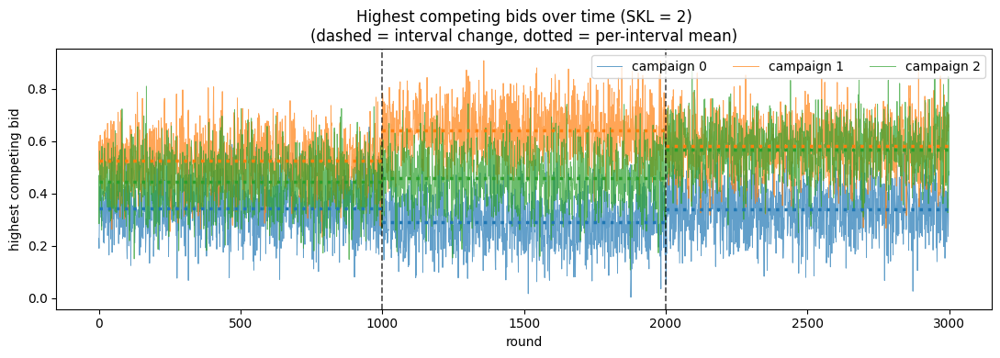


--- interval / mode 0 ---
  mu               : [0.3434 0.5198 0.4456]

--- interval / mode 1 ---
  mu               : [0.2886 0.6419 0.4638]

--- interval / mode 2 ---
  mu               : [0.3377 0.5822 0.5704]


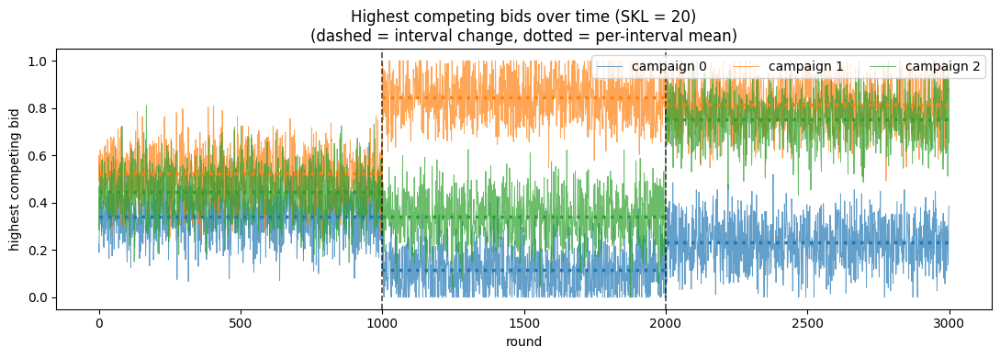


--- interval / mode 0 ---
  mu               : [0.3434 0.5198 0.4456]

--- interval / mode 1 ---
  mu               : [0.1093 0.8499 0.3465]

--- interval / mode 2 ---
  mu               : [0.2325 0.8132 0.7542]


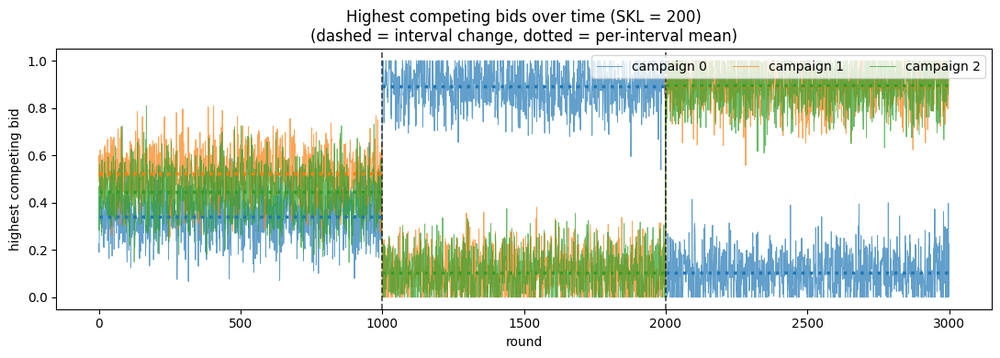


--- interval / mode 0 ---
  mu               : [0.3434 0.5198 0.4456]

--- interval / mode 1 ---
  mu               : [0.9 0.1 0.1]

--- interval / mode 2 ---
  mu               : [0.1 0.9 0.9]


In [80]:
for target_skl in [2, 20, 200] : 
    env_diffSKL = NonStationaryMultiCampaignEnvironment(
        number_of_campaigns=3,
        horizon=HORIZON,
        number_of_intervals=NUM_INTERVALS,
        budget=10000,                               # irrelevant to sequence generation
        target_skl=target_skl,
        max_std=0.1,
        constellation_seed=42,
        random_seed=42,
    )

    # Get the characteristic from the environment
    hcb = env_diffSKL.highest_competing_bids          
    boundaries = env_diffSKL.interval_boundaries       
    n_campaigns = env_diffSKL.number_of_campaigns
    n_intervals = env_diffSKL.number_of_intervals

    # Set colors for the plot
    colors = plt.cm.tab10(np.arange(n_campaigns))

    # Create the figure
    fig, ax = plt.subplots(figsize=(11, 4))

    # Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
    for c in range(n_campaigns):
        ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

    # Add a vertical line for each interval change.
    for b in boundaries[1:-1]:
        ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

    # For every interval add a line for the mean value of the highest competing bids across the interval.
    for k in range(n_intervals):
        lo, hi = boundaries[k], boundaries[k + 1]
        seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
        for c in range(n_campaigns):
            ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls=":", lw=2.5)

    # Set title, labels, legend and show the plot.
    ax.set_title(f"Highest competing bids over time (SKL = {target_skl})" + "\n(dashed = interval change, dotted = per-interval mean)")
    ax.set_xlabel("round")
    ax.set_ylabel("highest competing bid")
    ax.legend(loc="upper right", ncol=n_campaigns)

    plt.tight_layout()
    plt.show()
    
    modes = env_diffSKL.constellation
    max_std = env_diffSKL.max_std

    for k, (mu, sigma) in enumerate(modes):
        mu = np.asarray(mu); sigma = np.asarray(sigma)
        print(f"\n--- interval / mode {k} ---")
        print("  mu               :", np.round(mu, 4))

### Case with 10 campaigns and different values of SKL.

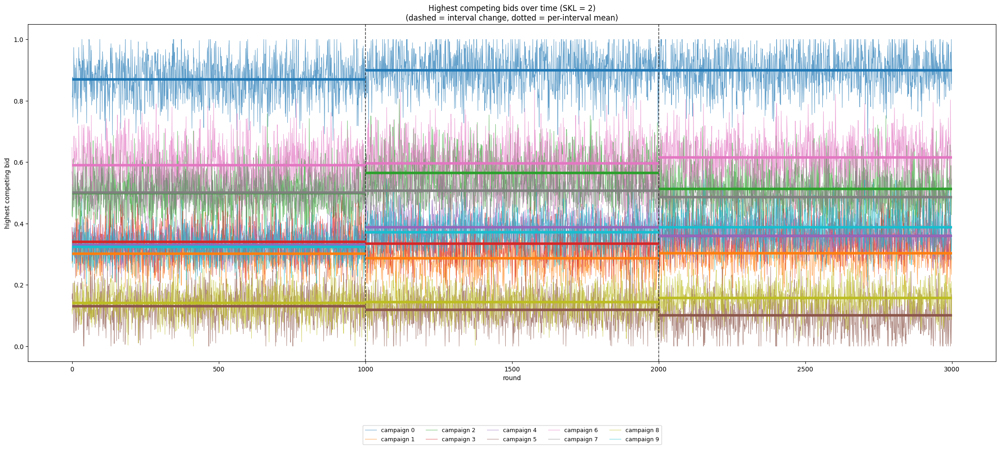


--- interval / mode 0 ---
  mu               : [0.87   0.3014 0.4978 0.3407 0.3279 0.1295 0.5877 0.5021 0.1412 0.3229]

--- interval / mode 1 ---
  mu               : [0.9    0.2888 0.565  0.3331 0.3855 0.1174 0.5973 0.503  0.1445 0.3713]

--- interval / mode 2 ---
  mu               : [0.9    0.3015 0.511  0.3617 0.3591 0.1    0.6169 0.4886 0.1589 0.3868]


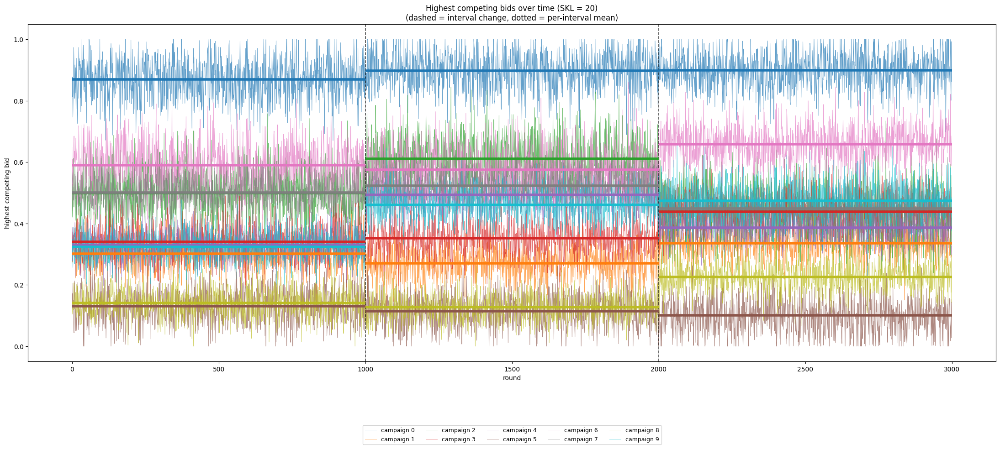


--- interval / mode 0 ---
  mu               : [0.87   0.3014 0.4978 0.3407 0.3279 0.1295 0.5877 0.5021 0.1412 0.3229]

--- interval / mode 1 ---
  mu               : [0.9    0.2719 0.6142 0.3486 0.4943 0.1146 0.5747 0.5203 0.128  0.4605]

--- interval / mode 2 ---
  mu               : [0.9    0.3345 0.437  0.44   0.3846 0.1    0.6596 0.4516 0.2276 0.4744]


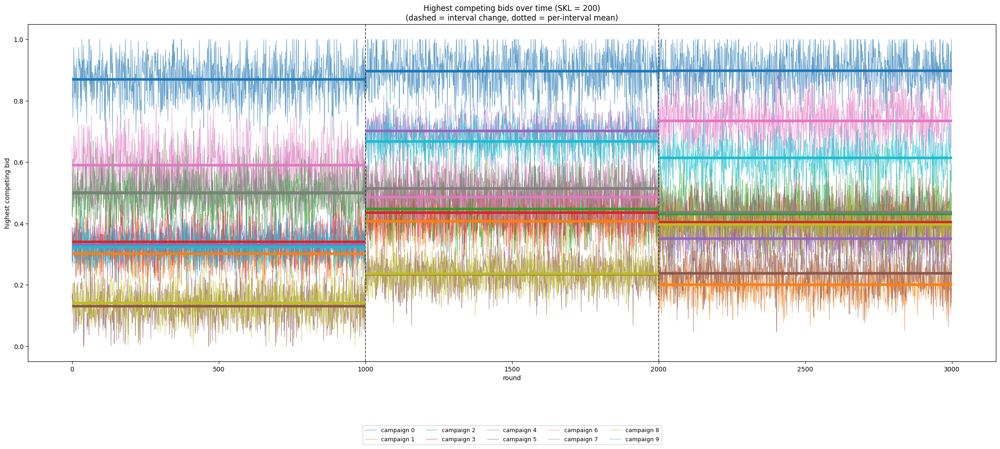


--- interval / mode 0 ---
  mu               : [0.87   0.3014 0.4978 0.3407 0.3279 0.1295 0.5877 0.5021 0.1412 0.3229]

--- interval / mode 1 ---
  mu               : [0.9    0.4081 0.4511 0.4316 0.7014 0.2353 0.4858 0.5101 0.2373 0.6682]

--- interval / mode 2 ---
  mu               : [0.9    0.1986 0.429  0.4064 0.3492 0.2372 0.7364 0.4395 0.3984 0.6134]


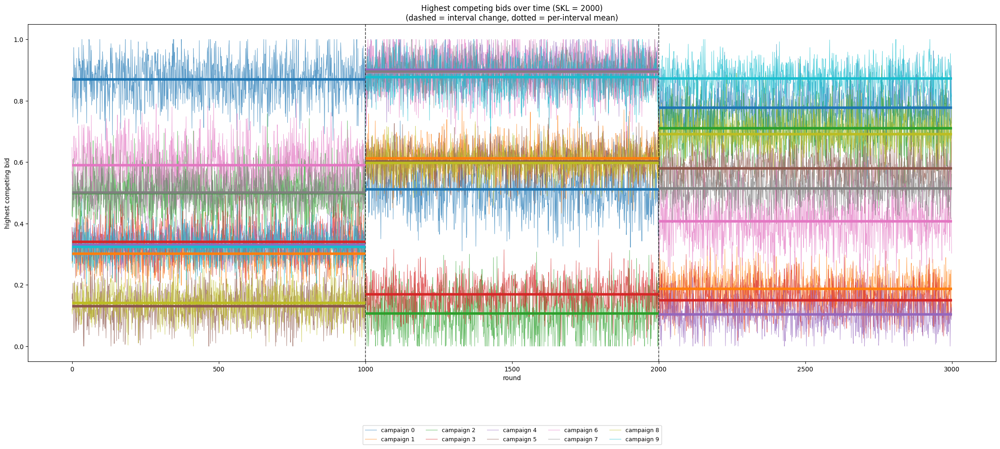


--- interval / mode 0 ---
  mu               : [0.87   0.3014 0.4978 0.3407 0.3279 0.1295 0.5877 0.5021 0.1412 0.3229]

--- interval / mode 1 ---
  mu               : [0.5124 0.6109 0.101  0.1661 0.8996 0.6017 0.8982 0.8932 0.5969 0.8755]

--- interval / mode 2 ---
  mu               : [0.7793 0.186  0.7118 0.151  0.103  0.5787 0.4079 0.5176 0.6921 0.8713]


In [81]:
for target_skl in [2, 20, 200, 2000] : 
    env_10cam_diffSKL = NonStationaryMultiCampaignEnvironment(
        number_of_campaigns=10,
        horizon=HORIZON,
        number_of_intervals=NUM_INTERVALS,
        budget=10000,                               # irrelevant to sequence generation
        target_skl=target_skl,
        max_std=0.1,
        constellation_seed=42,
        random_seed=42,
    )

    # Get the characteristic from the environment
    hcb = env_10cam_diffSKL.highest_competing_bids          
    boundaries = env_10cam_diffSKL.interval_boundaries       
    n_campaigns = env_10cam_diffSKL.number_of_campaigns
    n_intervals = env_10cam_diffSKL.number_of_intervals

    # Set colors for the plot
    colors = plt.cm.tab10(np.arange(n_campaigns))

    # Create the figure
    fig, ax = plt.subplots(figsize=(22, 10))

    # Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
    for c in range(n_campaigns):
        ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

    # Add a vertical line for each interval change.
    for b in boundaries[1:-1]:
        ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

    # For every interval add a line for the mean value of the highest competing bids across the interval.
    for k in range(n_intervals):
        lo, hi = boundaries[k], boundaries[k + 1]
        seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
        for c in range(n_campaigns):
            ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls="-", lw=4.0, alpha=1.0, zorder=5)

    # Set title, labels, legend and show the plot.
    ax.set_title(f"Highest competing bids over time (SKL = {target_skl})" + "\n(dashed = interval change, dotted = per-interval mean)")
    ax.set_xlabel("round")
    ax.set_ylabel("highest competing bid")
    ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=5,
    fontsize=9,
    frameon=True
)
    plt.savefig("highest_competing_bids_10_campaigns.png", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()
    
    modes = env_10cam_diffSKL.constellation
    max_std = env_10cam_diffSKL.max_std

    for k, (mu, sigma) in enumerate(modes):
        mu = np.asarray(mu); sigma = np.asarray(sigma)
        print(f"\n--- interval / mode {k} ---")
        print("  mu               :", np.round(mu, 4))

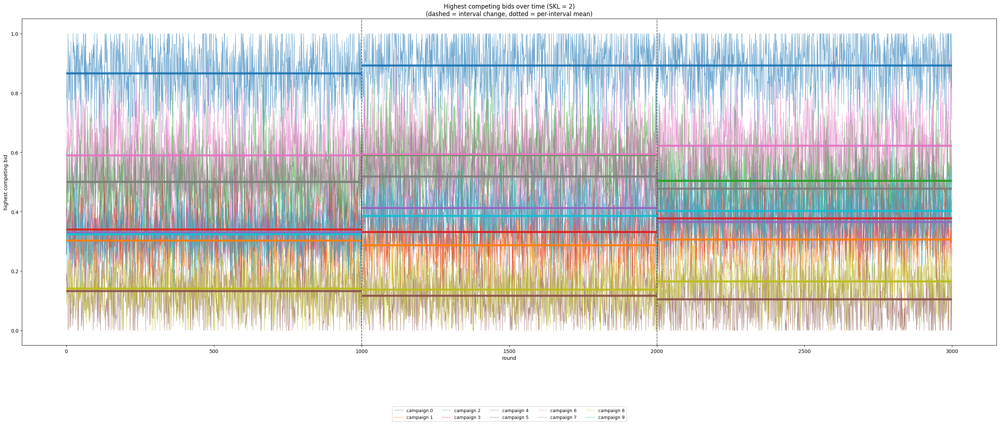


--- interval / mode 0 ---
  mu               : [0.87   0.3014 0.4978 0.3407 0.3279 0.1295 0.5877 0.5021 0.1412 0.3229]

--- interval / mode 1 ---
  mu               : [0.9    0.2913 0.5908 0.3295 0.4098 0.1133 0.5955 0.512  0.1396 0.3861]

--- interval / mode 2 ---
  mu               : [0.9    0.3041 0.5024 0.3787 0.3635 0.1    0.6249 0.4822 0.1672 0.4028]


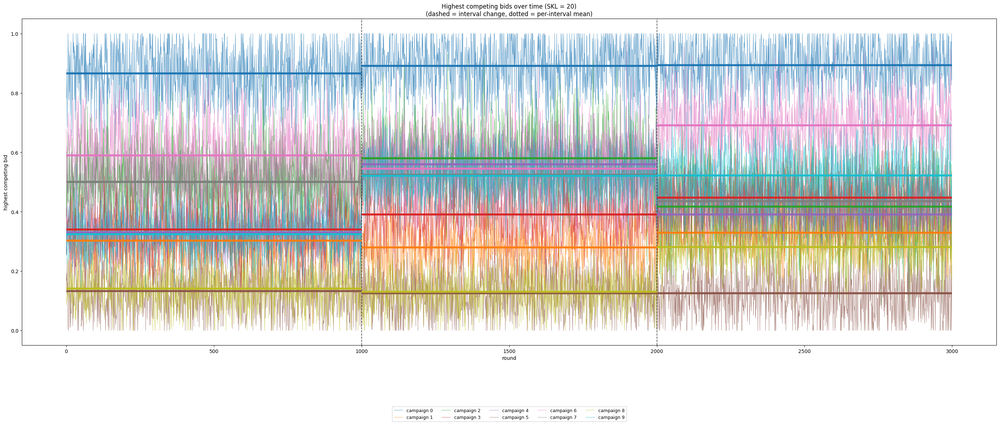


--- interval / mode 0 ---
  mu               : [0.87   0.3014 0.4978 0.3407 0.3279 0.1295 0.5877 0.5021 0.1412 0.3229]

--- interval / mode 1 ---
  mu               : [0.9    0.2817 0.5848 0.3862 0.5594 0.1239 0.5458 0.5199 0.1308 0.521 ]

--- interval / mode 2 ---
  mu               : [0.9    0.3271 0.4154 0.45   0.3896 0.121  0.6938 0.4395 0.2835 0.5214]


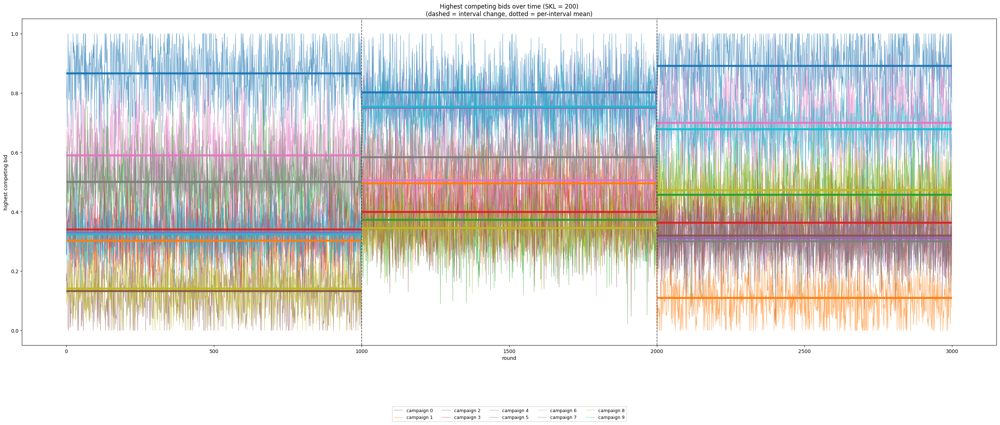


--- interval / mode 0 ---
  mu               : [0.87   0.3014 0.4978 0.3407 0.3279 0.1295 0.5877 0.5021 0.1412 0.3229]

--- interval / mode 1 ---
  mu               : [0.8044 0.4966 0.3778 0.3943 0.7507 0.3456 0.5049 0.5787 0.3468 0.7548]

--- interval / mode 2 ---
  mu               : [0.8998 0.1061 0.4561 0.3656 0.3065 0.3182 0.7009 0.3046 0.4734 0.678 ]


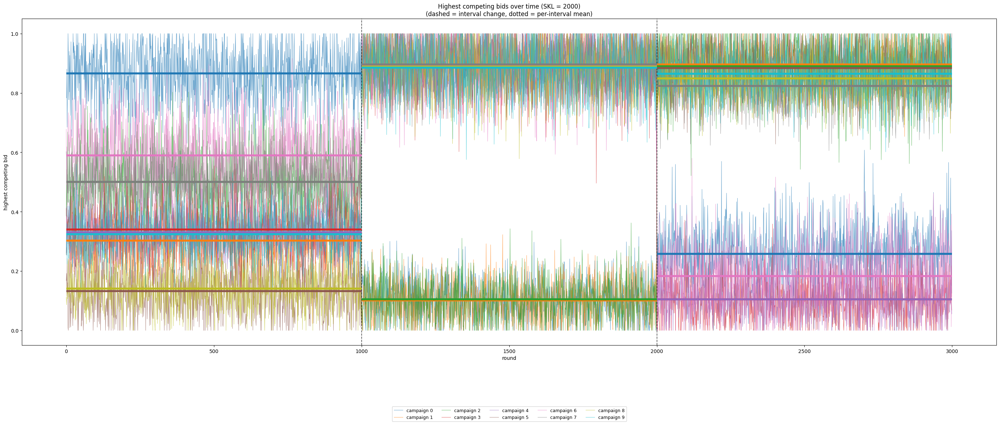


--- interval / mode 0 ---
  mu               : [0.87   0.3014 0.4978 0.3407 0.3279 0.1295 0.5877 0.5021 0.1412 0.3229]

--- interval / mode 1 ---
  mu               : [0.1017 0.101  0.101  0.8994 0.8996 0.893  0.8988 0.899  0.8974 0.8968]

--- interval / mode 2 ---
  mu               : [0.2592 0.8994 0.8996 0.1001 0.1001 0.8873 0.1844 0.8232 0.8474 0.8627]


In [82]:
for target_skl in [2, 20, 200, 2000] : 
    env_10cam_diffSKL = NonStationaryMultiCampaignEnvironment(
        number_of_campaigns=10,
        horizon=HORIZON,
        number_of_intervals=NUM_INTERVALS,
        budget=10000,                               # irrelevant to sequence generation
        target_skl=target_skl,
        max_std=0.15,
        constellation_seed=42,
        random_seed=42,
    )

    # Get the characteristic from the environment
    hcb = env_10cam_diffSKL.highest_competing_bids          
    boundaries = env_10cam_diffSKL.interval_boundaries       
    n_campaigns = env_10cam_diffSKL.number_of_campaigns
    n_intervals = env_10cam_diffSKL.number_of_intervals

    # Set colors for the plot
    colors = plt.cm.tab10(np.arange(n_campaigns))

    # Create the figure
    fig, ax = plt.subplots(figsize=(28, 12))

    # Get the highest competing bids for every campaign at each interval. Keeping one line per campaign.
    for c in range(n_campaigns):
        ax.plot(hcb[:, c], lw=0.7, alpha=0.7, color=colors[c], label=f"campaign {c}")

    # Add a vertical line for each interval change.
    for b in boundaries[1:-1]:
        ax.axvline(b, color="k", ls="--", lw=1.2, alpha=0.7)

    # For every interval add a line for the mean value of the highest competing bids across the interval.
    for k in range(n_intervals):
        lo, hi = boundaries[k], boundaries[k + 1]
        seg_mean = hcb[lo:hi].mean(axis=0)     # empirical mean for each campaign
        for c in range(n_campaigns):
            ax.hlines(seg_mean[c], lo, hi, color=colors[c], ls="-", lw=4.0, alpha=1.0, zorder=5)

    # Set title, labels, legend and show the plot.
    ax.set_title(f"Highest competing bids over time (SKL = {target_skl})" + "\n(dashed = interval change, dotted = per-interval mean)")
    ax.set_xlabel("round")
    ax.set_ylabel("highest competing bid")
    ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=5,
    fontsize=9,
    frameon=True
)
    plt.savefig("highest_competing_bids_10_campaigns.png", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()
    
    modes = env_10cam_diffSKL.constellation
    max_std = env_10cam_diffSKL.max_std

    for k, (mu, sigma) in enumerate(modes):
        mu = np.asarray(mu); sigma = np.asarray(sigma)
        print(f"\n--- interval / mode {k} ---")
        print("  mu               :", np.round(mu, 4))